# Import Libraries

In [1]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.tsa.stattools import kpss,adfuller
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# Download Financial Data

Download 10 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [2]:
#Εισαγωγή δεδομένων και τροποποίηση του συνόλου δεδομένων.
ticker_symbol = 'DX-Y.NYB'
ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df# Εμφάνιση του συνόλου δεδομένων

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
2510,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
2511,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
2512,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002


In [3]:
#Εμφάνισει των πρώτων στατιστικών, στρογγυλοποιημένες στο 3 δεκαδικό.
round(df.describe(),3)

,Open,High,Low,Close
count,2514.000,2514.000,2514.000,2514.000
mean,98.800,99.100,98.510,98.810
std,4.971,5.019,4.915,4.973
min,88.570,89.000,88.250,88.590
25%,95.172,95.530,94.992,95.172
50%,98.425,98.710,98.190,98.435
75%,102.457,102.758,102.070,102.455
max,114.190,114.780,113.330,114.110


Από τον παραπάνω πίνακα προκύπτει ότι :

*   Η μέση τιμή της τιμής ανοίγματος(Open) είναι 98.8 με τυπική απόκλιση 4.971. Η ελάχιστη τιμή ανοίγματος είναι 88.57 ενώ η μέγιστη διαμορφώνεται στα 114.19.
*   Η μέση τιμή της μέγιστης τιμής(High) είναι 99.1 με τυπική απόκλιση 5.019. Η ελάχιστη μέγιστη τιμή είναι 89 ενώ η μέγιστη διαμορφώνεται στα 114.78.
*   Η μέση τιμή της ελάχιστης τιμής (Low) είναι 98.51 με τυπική απόκλιση 4.915. Η ελάχιστη τιμή  είναι 88.25 ενώ η μέγιστη ελάχιστη τιμή διαμορφώνεται στα 113.33.
* Η μέση τιμή της τιμής κλεισίματος (Close) είναι 98.81 με τυπική απόκλιση 4.973. Η ελάχιστη τιμή κλεισίματος είναι 88.59 ενώ η μέγιστη διαμορφώνεται στα 114.11.



# Construct Line Plot of HLC Data

In [4]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2016 to 2026')
fig.show()

Από το παραπάνω πολύγωνο, παρατηρούμε ότι οι τρεις χρονοσειρές παρουσιάζουν εποχικότητα. Λόγω αυτού, οι χρονοσειρές **δεν είναι στάσιμες**. Υπόθεση που θα επιβεβαιώσουμε και με τα παρακάτω tests.



In [5]:
features=['Open','High','Low','Close']
for i in features:
  a =kpss(df[i],regression="c")
  b=adfuller(df[i])
  print(f'According to the KPSS test for the feature "{i}", the p-value is : {a[1]} and ADF test for the same feature gives a p-value : {round(b[1],3)}')

According to the KPSS test for the feature "Open", the p-value is : 0.01 and ADF test for the same feature gives a p-value : 0.343
According to the KPSS test for the feature "High", the p-value is : 0.01 and ADF test for the same feature gives a p-value : 0.34
According to the KPSS test for the feature "Low", the p-value is : 0.01 and ADF test for the same feature gives a p-value : 0.294
According to the KPSS test for the feature "Close", the p-value is : 0.01 and ADF test for the same feature gives a p-value : 0.336


Παρατηρούμε ότι και στις τρεις χρονοσειρές οι τιμές p-value για το KSS είναι μικρότερη από 0.01 ενώ για το ADF μεγαλύτερες από το 0.05. Αυτό σημαίνει ότι οι χρονοσειρές **δεν είναι στάσιμες**.

# Train-Test Split

Test set should start 1 time step after the end of train set.

In [6]:
#Διαχωρισμός σε train-test sets.
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape


((1759, 5), (785, 5))

# Construct Timeframes

*   x = <x[0], x[1], x[2], ... x[H-1]>
*   y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

**Important: Past target must be included in x to achieve good accuracy**

In [7]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [8]:
#train_df.head(5)

In [9]:
#x_train, y_train = construct_timeframes(train_df, H=30)# Δημιουργία συνόλων εκπαίδευσης για H=30
#print('x:', x_train[0],'\ny:', y_train[0])

# Fit Linear Regression Model

In [10]:
x_train, y_train = construct_timeframes(train_df, history_size)# Δημιουργία συνόλων εκπαίδευσης για H=30
x_test, y_test = construct_timeframes(test_df, history_size)# Δημιουργία συνόλων επικύρωσης για H=30

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((1729, 120), (1729,), (755, 120), (755,))

<Axes: title={'center': 'Train-Test MAE of Linear Regression with H=30'}, xlabel='Dataset', ylabel='MAE'>

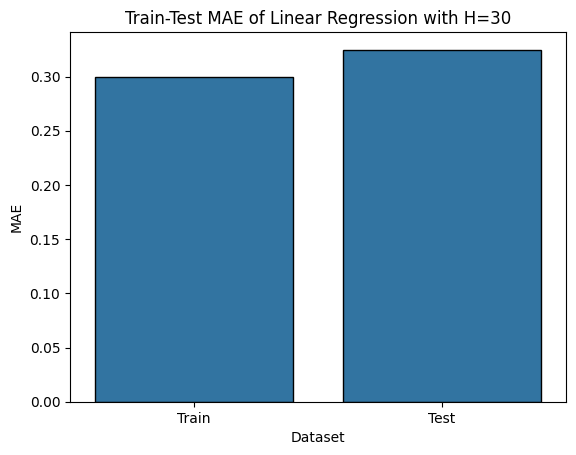

In [11]:
model = LinearRegression()# Δημιουργία μοντέλου γραμμικής παλινδρόμησης.
model.fit(x_train, y_train)# Εκπαίδευση μοντέλου

y_pred = model.predict(x_train) # Πρόβλεψη του y_train
train_mae = mean_absolute_error(y_true=y_train, y_pred=y_pred) # Υπολογισμός ΜΑΕ
y_pred = model.predict(x_test) # Πρόβλεψη του y_test
test_mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)# Υπολογισμός ΜΑΕ
#Δημιουργία ραβδογράμματος
metrics_df = pd.DataFrame({'Dataset': ['Train', 'Test'], 'MAE': [train_mae, test_mae]})
ax = sns.barplot(metrics_df, x='Dataset', y='MAE', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression with H=30')
ax

# Ελεγχος του μοντέλου για διαφορετικά H.

In [12]:
history= [1,5,15,30]# Τιμές ιστορικότητας
results=[] #Κενή λίστα που θα την εμπλουτίσουμε
for h in history:

  num_train_samples = int(df.shape[0]*train_size)
  train_df_h = df.iloc[:num_train_samples]
  test_df_h= df.iloc[num_train_samples - h:]

  x_train_h, y_train_h = construct_timeframes(train_df_h, h)# Δημιουργία συνόλων εκπαίδευσης για H=h
  x_test_h, y_test_h= construct_timeframes(test_df_h, h)# Δημιουργία συνόλων επικύρωσης για H=h

  model.fit(x_train_h, y_train_h) # Επανεκπαίδευση μοντέλου

  y_pred_h = model.predict(x_train_h)# Πρόβλεψη του y_train_h
  train_mae_h= mean_absolute_error(y_true=y_train_h, y_pred=y_pred_h)# Υπολογισμός ΜΑΕ
  y_pred_h = model.predict(x_test_h)# Πρόβλεψη του y_test_h
  test_mae_h= mean_absolute_error(y_true=y_test_h, y_pred=y_pred_h)# Υπολογισμός ΜΑΕ
#Εμπλουτισμός λίστα με το mae για train και test σύνολο για κάθε τιμή του h.
  results.append({'H': h, 'Dataset': 'Train', 'MAE': train_mae_h})
  results.append({'H': h, 'Dataset': 'Test', 'MAE': test_mae_h})

results_df=pd.DataFrame(results)


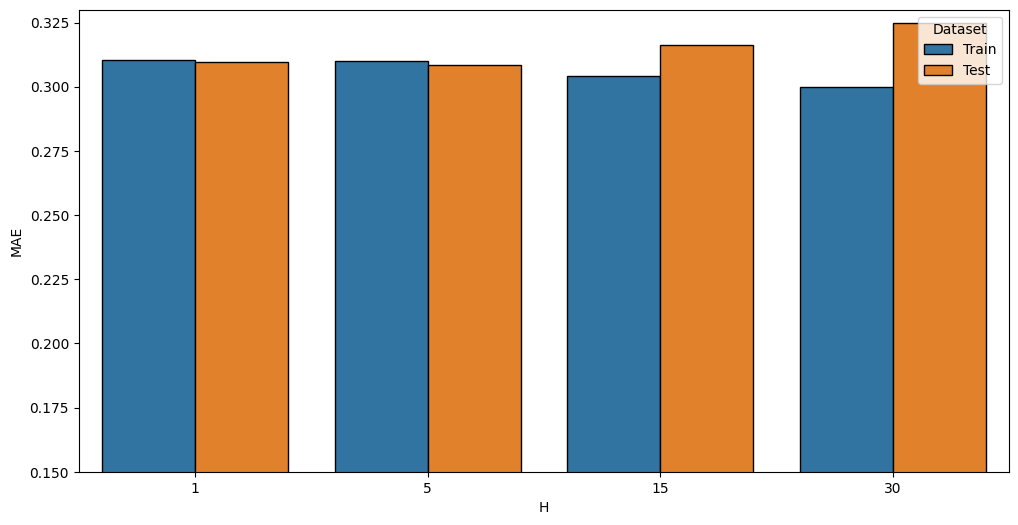

In [13]:
#Δημιουργία ραβδογράμματος.
plt.figure(figsize=(12,6))
plt.ylim(0.15,0.33)

ax = sns.barplot(results_df, x='H', y='MAE', hue='Dataset',edgecolor='black')

plt.show()


In [14]:
print(f'MAE for each H and Dataset type is :\n {results_df}')

MAE for each H and Dataset type is :
     H Dataset       MAE
0   1   Train  0.310360
1   1    Test  0.309556
2   5   Train  0.309919
3   5    Test  0.308628
4  15   Train  0.304049
5  15    Test  0.316398
6  30   Train  0.299845
7  30    Test  0.324738


Όπως προκύτει τόσο από το ραβδόγραμμα όσο και από τον παραπάνω πίνακα, τα MAEs για τα δύο σύνολα δεδομένων και για κάθε H=[1,5,15,30] είναι πολύ κοντά. Αυτό σημαίνει ότι το μοντέλο μπορεί να κάνει καλές πορβλέψεις.

# Visualize Predictions

In [15]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train',
    line=dict(color='royalblue', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index — Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()

Παρατηρούμε ότι οι προβλεπόμενες τιμές βρίσκονται πολύ κοντά στις πραγματικές τιμές κλεισίματος.

# Apply Log Returns Transformation

In [16]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()#Αντίγραφο του data frame
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))#Τύπος μετασχηματισμού
df_logr

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,NaN,NaN,NaN,NaN
1,2016-11-01 00:00:00-04:00,0.000712,-0.002231,-0.006635,-0.007647
2,2016-11-02 00:00:00-04:00,-0.006526,-0.006929,-0.004722,-0.003075
3,2016-11-03 00:00:00-04:00,-0.003792,-0.003483,-0.001442,-0.002467
4,2016-11-04 00:00:00-04:00,-0.002262,-0.001129,-0.001547,-0.000927
...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,-0.001377,-0.000294,0.000394,0.001966
2510,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472
2511,2026-10-27 00:00:00-04:00,0.002453,0.003326,0.004028,0.003525
2512,2026-10-28 00:00:00-04:00,0.003327,0.000878,0.000588,-0.001271


# Convert Log Returns to Absolute Price

$lr_{t+1} = \ln(\frac{y_{t+1}}{y_{t}})$

$y_{t+1} = y_t * e^{lr_{t+1}}$

Inevitably, the first sample will be lost, as its log-return transformation cannot be defined (x[-1] does not exist).

In [17]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns) #Ορισμός συνάρτηση για απόλυτες τιμές της μεταβλητής "prices".

In [18]:
valid_df = pd.DataFrame({ #Αφαίρεση του πρώτου στοιχείου γιατι ήταν NaN και reset τους δείκτες, δημιουργία νέου df.
    'Date': df['Date'].iloc[1:],
    'Close': df['Close'].iloc[1:],
    'CLose-Log-Returns': df_logr['Close'].iloc[1:]
}).reset_index()
valid_df

,index,Date,Close,CLose-Log-Returns
0,1,2016-11-01 00:00:00-04:00,97.699997,-0.007647
1,2,2016-11-02 00:00:00-04:00,97.400002,-0.003075
2,3,2016-11-03 00:00:00-04:00,97.160004,-0.002467
3,4,2016-11-04 00:00:00-04:00,97.070000,-0.000927
4,5,2016-11-07 00:00:00-05:00,97.779999,0.007288
...,...,...,...,...
2508,2509,2026-10-23 00:00:00-04:00,101.809998,0.001966
2509,2510,2026-10-26 00:00:00-04:00,101.959999,0.001472
2510,2511,2026-10-27 00:00:00-04:00,102.320000,0.003525
2511,2512,2026-10-28 00:00:00-04:00,102.190002,-0.001271


In [19]:
log_returns_to_absolute_prices(
   prices=valid_df['Close'].iloc[:].to_numpy(), log_returns=valid_df['CLose-Log-Returns'].iloc[:].to_numpy())

array([ 96.95571051,  97.10092726,  96.92059716, ..., 102.6812714 ,
       102.06017035, 101.87423722])

In [20]:
def construct_timeframes_2(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['CLose-Log-Returns'].to_numpy(dtype=np.float64)[H:]
    return x, y

In [21]:
valid_df

,index,Date,Close,CLose-Log-Returns
0,1,2016-11-01 00:00:00-04:00,97.699997,-0.007647
1,2,2016-11-02 00:00:00-04:00,97.400002,-0.003075
2,3,2016-11-03 00:00:00-04:00,97.160004,-0.002467
3,4,2016-11-04 00:00:00-04:00,97.070000,-0.000927
4,5,2016-11-07 00:00:00-05:00,97.779999,0.007288
...,...,...,...,...
2508,2509,2026-10-23 00:00:00-04:00,101.809998,0.001966
2509,2510,2026-10-26 00:00:00-04:00,101.959999,0.001472
2510,2511,2026-10-27 00:00:00-04:00,102.320000,0.003525
2511,2512,2026-10-28 00:00:00-04:00,102.190002,-0.001271


valid_df

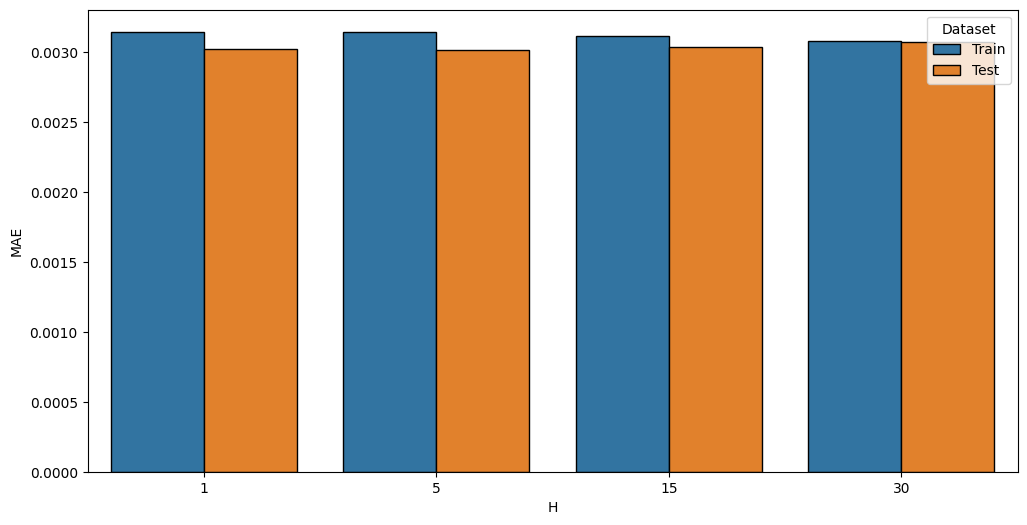

In [22]:
history= [1,5,15,30]# Τιμές ιστορικότητας
results=[] #Κενή λίστα που θα την εμπλουτίσουμε
for h in history:
  num_train_samples = int(valid_df.shape[0]*train_size)
  train_df_h = valid_df.iloc[:num_train_samples]
  test_df_h= valid_df.iloc[num_train_samples - h:]

  x_train_h, y_train_h = construct_timeframes_2(train_df_h, h)# Δημιουργία συνόλων εκπαίδευσης για H=h
  x_test_h, y_test_h= construct_timeframes_2(test_df_h, h)# Δημιουργία συνόλων επικύρωσης για H=h

  model.fit(x_train_h, y_train_h) # Επανεκπαίδευση μοντέλου

  y_pred_h = model.predict(x_train_h)# Πρόβλεψη του y_train_h
  train_mae_h= mean_absolute_error(y_true=y_train_h, y_pred=y_pred_h)# Υπολογισμός ΜΑΕ
  y_pred_h = model.predict(x_test_h)# Πρόβλεψη του y_test_h
  test_mae_h= mean_absolute_error(y_true=y_test_h, y_pred=y_pred_h)# Υπολογισμός ΜΑΕ
#Εμπλουτισμός λίστα με το mae για train και test σύνολο για κάθε τιμή του h.
  results.append({'H': h, 'Dataset': 'Train', 'MAE': train_mae_h})
  results.append({'H': h, 'Dataset': 'Test', 'MAE': test_mae_h})

results_df=pd.DataFrame(results)


#Δημιουργία ραβδογράμματος.
plt.figure(figsize=(12,6))

ax = sns.barplot(results_df, x='H', y='MAE', hue='Dataset',edgecolor='black')

plt.show()


In [23]:
round(results_df,3)

,H,Dataset,MAE
0,1,Train,0.003
1,1,Test,0.003
2,5,Train,0.003
3,5,Test,0.003
4,15,Train,0.003
5,15,Test,0.003
6,30,Train,0.003
7,30,Test,0.003


# Check Whether High can Predict Close

Variables that can estimate the target variable are considered beneficial.

In [24]:
data = train_df[['Close', 'Open']]

# Computing log-returns (converting to stationary series).
data = np.log(data/data.shift(1)).dropna()

# Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

# Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.191609,False
1,2,0.820257,False
2,3,0.525268,False
3,4,0.785338,False
4,5,0.025691,True
5,6,0.636667,False
6,7,0.725205,False
7,8,0.392926,False
8,9,0.278278,False
9,10,0.493648,False


Από τα παραπάνω αποτελέσματα προκύπτει ότι το χρονικό βήμα 4 θεωρείται σημαντικό.

# Extracting Temporal Features

In [25]:
# Calendar features
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

# US & NYSE holidays
us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')

# Global events
global_events = {
    'NewYearsDay': (1, 1),
    'ValentinesDay': (2, 14),
    'WomensDay': (3, 8),
    'AprilFools': (4, 1),
    'EarthDay': (4, 22),
    'LabourDay': (5, 1),
    'EnvironmentDay': (6, 5),
    'Halloween': (10, 31),
    'ChristmasEve': (12, 24),
    'ChristmasDay': (12, 25),
    'BoxingDay': (12, 26),
    'NewYearsEve': (12, 31),
}

event_dates = set(global_events.values())

# Combine US holidays, NYSE holidays, and global events
df['IsHoliday'] = df['Date'].dt.date.map(
    lambda d: int(
        d in us_holidays
        or d in nyse_holidays
        or (d.month, d.day) in event_dates
    )
)

df

,Date,Open,High,Low,Close,Month,DayOfWeek,IsHoliday
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997,10,0,1
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997,11,1,0
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002,11,2,0
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004,11,3,0
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000,11,4,0
...,...,...,...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998,10,4,0
2510,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999,10,0,0
2511,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000,10,1,0
2512,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002,10,2,0


In [26]:
df['IsHoliday'].value_counts()

,count
IsHoliday,
0,2422
1,92
